## 1. Predict, compare, and learn

Setelah jaringan membuat prediksi (*predict*), prediksi dibandingkan dengan target (*compare*) untuk mengukur kesalahan. Kemudian weight diperbarui (*learn*) agar error berkurang. Error memberi tahu seberapa jauh prediksi meleset, tetapi kita juga perlu menentukan arah dan besar perubahan weight.

## 2. Mengukur error

Untuk satu prediksi, digunakan squared error:


E=(prediction-target)$^2$

Untuk sejumlah prediksi, *mean squared error* (MSE) adalah rata-rata kuadrat selisih. Kuadrat membuat error tidak negatif dan memberi penalti lebih besar pada selisih yang besar.

In [1]:
prediction = 0.8
target = 1.0
error = (prediction - target) ** 2
print("Prediction:", prediction)
print("Target:", target)
print("Squared error:", error)

Prediction: 0.8
Target: 1.0
Squared error: 0.03999999999999998


In [2]:
predictions = [0.8, 0.4, 0.9]
targets = [1.0, 0.0, 1.0]
errors = [(p - t) ** 2 for p, t in zip(predictions, targets)]
mse = sum(errors) / len(errors)
print("Squared errors:", errors)
print("MSE:", mse)

Squared errors: [0.03999999999999998, 0.16000000000000003, 0.009999999999999995]
MSE: 0.07


## 3. Model satu input dan satu weight

Model sederhana `prediction = input × weight`. Kita dapat menghitung prediksi dan error sebelum belajar.

In [3]:
input_value = 0.5
weight = 0.1
target = 0.8

def neural_network(input_value, weight):
    return input_value * weight

prediction = neural_network(input_value, weight)
error = (prediction - target) ** 2
print("Prediction:", prediction)
print("Target:", target)
print("Squared error:", error)

Prediction: 0.05
Target: 0.8
Squared error: 0.5625


## 4. Hot and cold learning

Metode *hot and cold learning* menguji perubahan weight kecil ke atas dan ke bawah, menghitung error dari masing-masing percobaan, lalu memilih arah yang menghasilkan error lebih rendah. Metode ini intuitif, tetapi memerlukan percobaan untuk menguji arah perubahan.

In [4]:
input_value = 0.5
target = 0.8
weight = 0.1
step = 0.01

def predict(x, w):
    return x * w

def squared_error(prediction, target):
    return (prediction - target) ** 2

base_error = squared_error(predict(input_value, weight), target)
up_error = squared_error(predict(input_value, weight + step), target)
down_error = squared_error(predict(input_value, weight - step), target)

print("Current:", weight, base_error)
print("Weight increased:", weight + step, up_error)
print("Weight decreased:", weight - step, down_error)

Current: 0.1 0.5625
Weight increased: 0.11 0.555025
Weight decreased: 0.09000000000000001 0.570025


## 5. Derivative: arah perubahan error

Untuk model `prediction = input × weight` dan squared error, turunan terhadap weight adalah:

$
\frac{dE}{dweight}=2(prediction-target)\,input
$

Derivative memberi informasi tentang kemiringan error. Gradient descent bergerak berlawanan arah dari derivative untuk mencari error yang lebih rendah.

In [5]:
input_value = 0.5
weight = 0.1
target = 0.8

prediction = input_value * weight
error = (prediction - target) ** 2
derivative = 2 * (prediction - target) * input_value

print("Prediction:", prediction)
print("Squared error:", error)
print("Derivative:", derivative)

Prediction: 0.05
Squared error: 0.5625
Derivative: -0.75


## 6. Satu iterasi gradient descent

$
weight\_delta=-\alpha\frac{dE}{dweight}
$

$
weight_{new}=weight_{old}+weight\_delta
$

`alpha` adalah *learning rate*, yaitu pengatur besar langkah pembaruan. Tanda negatif membuat weight bergerak berlawanan arah dari derivative.

In [6]:
input_value = 0.5
weight = 0.1
target = 0.8
alpha = 0.1

prediction = input_value * weight
error_before = (prediction - target) ** 2
derivative = 2 * (prediction - target) * input_value
weight_delta = -alpha * derivative
new_weight = weight + weight_delta
new_prediction = input_value * new_weight
error_after = (new_prediction - target) ** 2

print("Weight before:", weight)
print("Prediction before:", prediction)
print("Error before:", error_before)
print("Derivative:", derivative)
print("Weight delta:", weight_delta)
print("Weight after:", new_weight)
print("Prediction after:", new_prediction)
print("Error after:", error_after)

Weight before: 0.1
Prediction before: 0.05
Error before: 0.5625
Derivative: -0.75
Weight delta: 0.07500000000000001
Weight after: 0.17500000000000002
Prediction after: 0.08750000000000001
Error after: 0.50765625


## 7. Mengulangi proses belajar

Setiap iterasi melakukan prediksi, menghitung error, menghitung derivative, lalu memperbarui weight. Dengan data sederhana ini, kita dapat mengamati apakah error turun dari waktu ke waktu.

In [7]:
input_value = 0.5
target = 0.8
weight = 0.1
alpha = 0.1

print("iteration | prediction | error | updated weight")
for iteration in range(10):
    prediction = input_value * weight
    error = (prediction - target) ** 2
    derivative = 2 * (prediction - target) * input_value
    weight += -alpha * derivative
    print(f"{iteration+1:9d} | {prediction:10.6f} | {error:.6f} | {weight:.6f}")

print("Final prediction:", input_value * weight)
print("Final error:", (input_value * weight - target) ** 2)

iteration | prediction | error | updated weight
        1 |   0.050000 | 0.562500 | 0.175000
        2 |   0.087500 | 0.507656 | 0.246250
        3 |   0.123125 | 0.458160 | 0.313938
        4 |   0.156969 | 0.413489 | 0.378241
        5 |   0.189120 | 0.373174 | 0.439329
        6 |   0.219664 | 0.336790 | 0.497362
        7 |   0.248681 | 0.303953 | 0.552494
        8 |   0.276247 | 0.274317 | 0.604869
        9 |   0.302435 | 0.247571 | 0.654626
       10 |   0.327313 | 0.223433 | 0.701895
Final prediction: 0.35094729557121584
Final error: 0.20164833135480503


## 8. Mengapa `weight_delta` penting?

`weight_delta` dihitung dari derivative dan learning rate. Derivative menunjukkan arah serta sensitivitas error terhadap weight; `alpha` mengatur besar langkah. Learning rate yang terlalu kecil dapat membuat pembelajaran lambat, sedangkan nilai yang terlalu besar dapat menyebabkan pembaruan berlebihan.

## 9. Learning rate dan divergensi

Jika langkah pembaruan terlalu besar, weight bisa melompat melewati nilai yang lebih baik. Ketika proses menjauh dari solusi atau error membesar, perilaku ini disebut *divergence*. Coba beberapa nilai `alpha` untuk membandingkan hasil.

In [8]:
def train_with_alpha(alpha, iterations=10):
    x, target, weight = 0.5, 0.8, 0.1
    for _ in range(iterations):
        prediction = x * weight
        derivative = 2 * (prediction - target) * x
        weight += -alpha * derivative
    prediction = x * weight
    return weight, prediction, (prediction - target) ** 2

for alpha in [0.01, 0.1, 0.5, 1.5]:
    weight, prediction, error = train_with_alpha(alpha)
    print(f"alpha={alpha:>4}: weight={weight:.6f}, prediction={prediction:.6f}, error={error:.6f}")

alpha=0.01: weight=0.173335, prediction=0.086667, error=0.508843
alpha= 0.1: weight=0.701895, prediction=0.350947, error=0.201648
alpha= 0.5: weight=1.515530, prediction=0.757765, error=0.001784
alpha= 1.5: weight=1.599999, prediction=0.799999, error=0.000000


## 10. Visualisasi error selama pembelajaran

Grafik ini membandingkan error selama beberapa iterasi untuk beberapa learning rate.

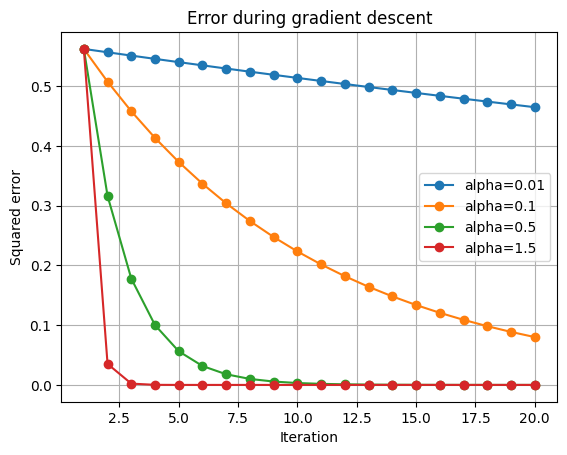

In [9]:
import matplotlib.pyplot as plt

def error_history(alpha, iterations=20):
    x, target, weight = 0.5, 0.8, 0.1
    errors = []
    for _ in range(iterations):
        prediction = x * weight
        errors.append((prediction - target) ** 2)
        derivative = 2 * (prediction - target) * x
        weight += -alpha * derivative
    return errors

for alpha in [0.01, 0.1, 0.5, 1.5]:
    plt.plot(range(1, 21), error_history(alpha), marker="o", label=f"alpha={alpha}")
plt.xlabel("Iteration")
plt.ylabel("Squared error")
plt.title("Error during gradient descent")
plt.legend()
plt.grid(True)
plt.show()